# 📝 Real-World Custom Handwritten Trials
### Evaluating Pre-Trained Benchmark Models on Unseen Real-World Handwriting (Domain Shift Analysis)

* **Pre-Trained Model**: Support Vector Classifier (`models/best_digits_svm_model.joblib`) trained on the Scikit-Learn Digits benchmark (>99% accuracy in `handwritten_digit_recognition.ipynb`).
* **Trial 1 Dataset**: Smartphone photo (`data/custom_trials/trial_01_phone_lined_paper/self.jpeg`) of 10 digits (`0` to `9`) written horizontally in blue ballpoint ink on red-lined paper (**50% accuracy**).
* **Trial 2 Dataset**: Second smartphone photo (`data/custom_trials/trial_02_vertical_column/sample_02.jpeg`) of 10 digits (`0` to `9`) written in a single **vertical column** on lined paper (**20% accuracy**).
* **Core Objective**: Experience and analyze **Domain Shift** firsthand:
  - Why does a model with **>99% lab accuracy** drop to **50% in Trial 1** and **20% in Trial 2**?
  - How computer vision preprocessing (ink thresholding, rule-line filtering, morphological dilation, aspect-ratio preservation) bridges the gap between raw camera photos and $8 \times 8$ pixel inputs.

---

### Notebook Outline:
1. **Model Loading & Verification**: Loading pre-trained SVM model and scaler artifacts from `models/`.
2. **Trial 1 Deep Dive (2-Row Horizontal Layout)**:
   - Orientation correction & why naive grayscale thresholding fails on notebook lines.
   - Blue ink segmentation: `(b - r) > 10`.
   - Morphological stroke dilation matching NIST stroke thickness.
   - Multi-digit evaluation & accuracy analysis (50.0%).
3. **Trial 2 Deep Dive (Single Vertical Column Layout)**:
   - Suppressing horizontal rule lines with morphological grey opening.
   - Automated vertical digit segmentation (0 at top, down to 9 at bottom).
   - Multi-digit evaluation & accuracy analysis (20.0%).
4. **Single-Digit Custom Inference**: Testing arbitrary external samples (`sample_digit_3.png` and `sample_digit_0.png`) with confidence distributions.
5. **Cross-Trial Comparison & Domain Shift Takeaways**:
   - Why lab 99% $\rightarrow$ Trial 1 50% $\rightarrow$ Trial 2 20%?
   - Architectural lessons on resolution, aspect ratio distortion, and real-world deployment.


In [1]:
# Environment & Library Setup
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from PIL import Image
import scipy.ndimage as ndi

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("✅ Libraries successfully loaded.")


✅ Libraries successfully loaded.


## 1. Load Pre-Trained Benchmark Model & Scaler

We load the Support Vector Classifier (`best_digits_svm_model.joblib`) and Min-Max Scaler (`minmax_scaler.joblib`) trained in the benchmark notebook (`handwritten_digit_recognition.ipynb`).


In [2]:
# Load pre-trained benchmark artifacts
MODEL_PATH = "models/best_digits_svm_model.joblib"
SCALER_PATH = "models/minmax_scaler.joblib"

assert os.path.exists(MODEL_PATH), f"Model not found at {MODEL_PATH}. Run benchmark first!"
assert os.path.exists(SCALER_PATH), f"Scaler not found at {SCALER_PATH}. Run benchmark first!"

model = joblib.load(MODEL_PATH)
scaler = joblib.load(SCALER_PATH)

print(f"✅ Loaded Trained Model: {type(model).__name__}")
print(f"   Model Parameters: C={model.C}, gamma={model.gamma}, kernel='{model.kernel}'")
print(f"   Number of classes: {len(model.classes_)} ({list(model.classes_)})")
print(f"✅ Loaded Scaler: {type(scaler).__name__} (Feature range: {scaler.feature_range})")


✅ Loaded Trained Model: SVC
   Model Parameters: C=5, gamma=0.05, kernel='rbf'
   Number of classes: 10 ([np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)])
✅ Loaded Scaler: MinMaxScaler (Feature range: (0, 1))


## 2. Real-World Trial 1: Horizontal Two-Row Layout (`self.jpeg`)

In Trial 1, 10 handwritten digits (`0` through `9`) were written horizontally across two rows with blue ballpoint pen on red-lined paper.


✅ Trial 1: Successfully segmented 10 digit components.


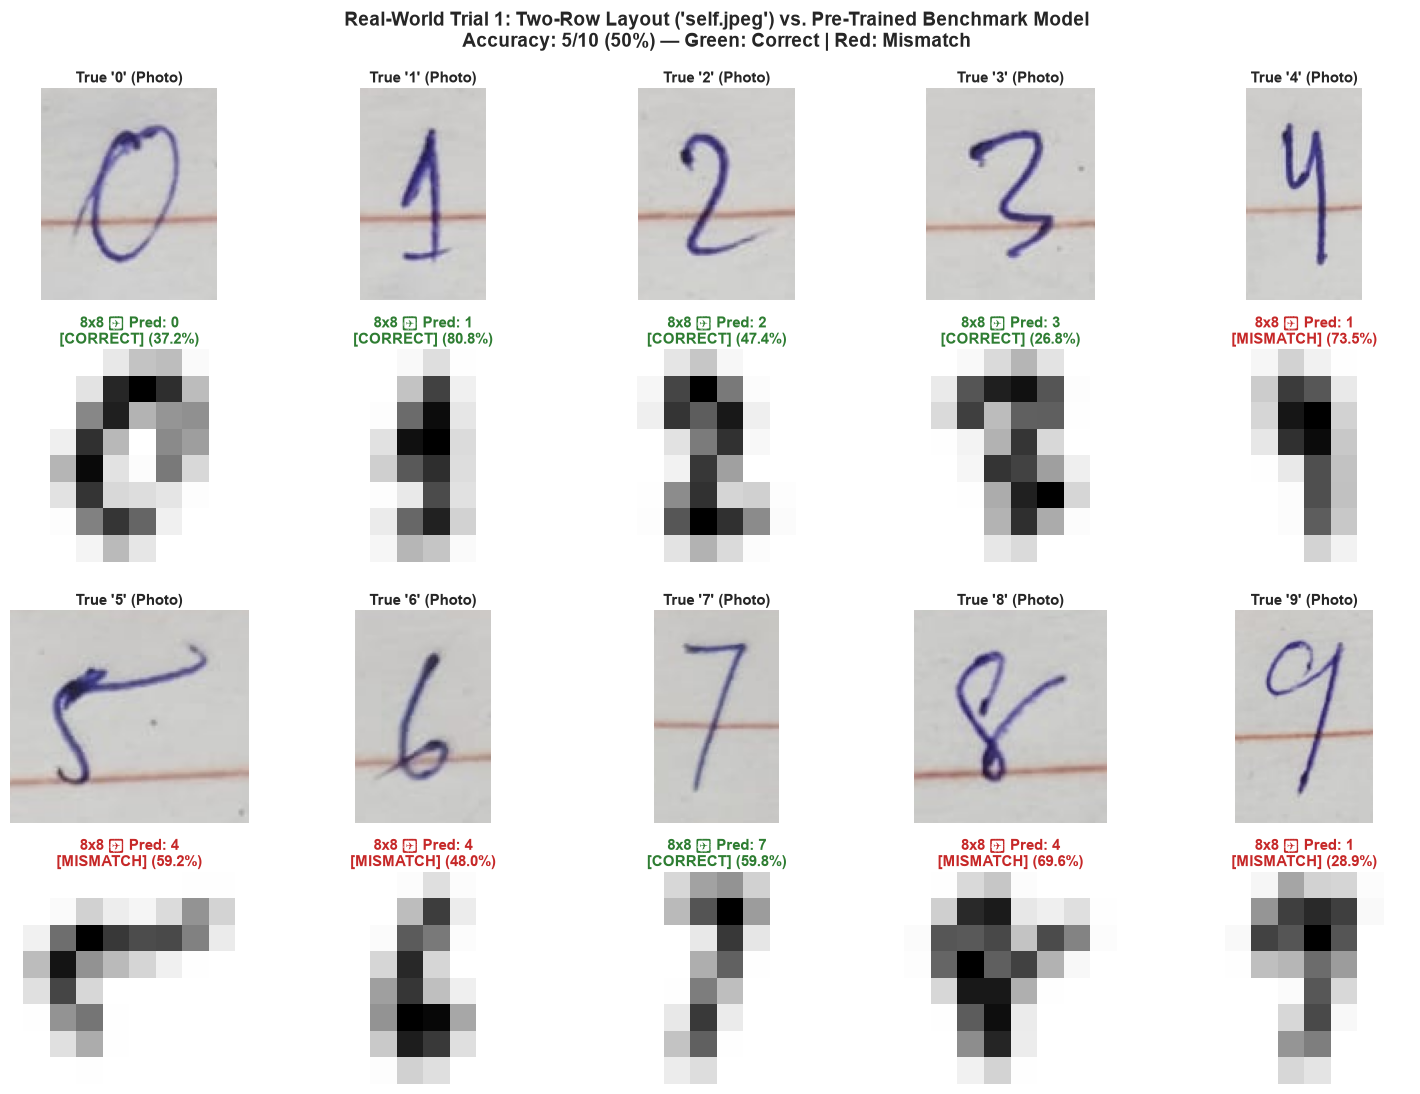

📊 TRIAL 1 ACCURACY: 5/10 (50%)
 True Digit  Predicted Confidence (%)   Result
          0          0          37.2%  CORRECT
          1          1          80.8%  CORRECT
          2          2          47.4%  CORRECT
          3          3          26.8%  CORRECT
          4          1          73.5% MISMATCH
          5          4          59.2% MISMATCH
          6          4          48.0% MISMATCH
          7          7          59.8%  CORRECT
          8          4          69.6% MISMATCH
          9          1          28.9% MISMATCH


In [3]:
# Load Trial 1 raw image
TRIAL1_IMG_PATH = "data/custom_trials/trial_01_phone_lined_paper/self.jpeg"
raw_img1 = Image.open(TRIAL1_IMG_PATH)

# Correct orientation (90 degrees counter-clockwise)
oriented_img1 = raw_img1.rotate(90, expand=True)
arr_rgb1 = np.array(oriented_img1, dtype=np.float32)

# Isolate blue ballpoint ink using color difference ((b - r) > 10)
r, g, b = arr_rgb1[:, :, 0], arr_rgb1[:, :, 1], arr_rgb1[:, :, 2]
brightness = (r + g + b) / 3.0
blue_ink_mask = (brightness < 160) & ((b - r) > 10)

# Segment the 10 digits across 2 rows
segment_dilated = ndi.binary_dilation(blue_ink_mask, iterations=6)
labeled, num_features = ndi.label(segment_dilated)
objects = ndi.find_objects(labeled)

boxes1 = []
for sl in objects:
    if np.sum(blue_ink_mask[sl]) > 100:
        boxes1.append((sl[0].start, sl[0].stop, sl[1].start, sl[1].stop))

row1 = sorted([bx for bx in boxes1 if (bx[0] + bx[1]) / 2 < 300], key=lambda bx: bx[2])
row2 = sorted([bx for bx in boxes1 if (bx[0] + bx[1]) / 2 >= 300], key=lambda bx: bx[2])
digits_order1 = row1 + row2

print(f"✅ Trial 1: Successfully segmented {len(digits_order1)} digit components.")

# Plot Trial 1 4x5 Evaluation Gallery
fig, axes = plt.subplots(4, 5, figsize=(15, 11))
correct_count1 = 0
results_table1 = []

for true_digit, (ymin, ymax, xmin, xmax) in enumerate(digits_order1[:10]):
    col = true_digit % 5
    row_photo = 0 if true_digit < 5 else 2
    row_8x8 = 1 if true_digit < 5 else 3
    
    pad_raw = 15
    y0 = max(0, ymin - pad_raw)
    y1 = min(arr_rgb1.shape[0], ymax + pad_raw)
    x0 = max(0, xmin - pad_raw)
    x1 = min(arr_rgb1.shape[1], xmax + pad_raw)
    raw_crop = arr_rgb1[y0:y1, x0:x1].astype(np.uint8)
    
    crop_mask = blue_ink_mask[ymin:ymax, xmin:xmax]
    crop_thick = ndi.binary_dilation(crop_mask, iterations=3).astype(np.float32) * 255.0
    
    h, w = crop_thick.shape
    size = max(h, w)
    pad = int(size * 0.08)
    tot = size + 2 * pad
    sq = np.zeros((tot, tot), dtype=np.float32)
    sq[pad + (size - h) // 2 : pad + (size - h) // 2 + h,
       pad + (size - w) // 2 : pad + (size - w) // 2 + w] = crop_thick
    
    res = Image.fromarray(sq.astype(np.uint8)).resize((8, 8), Image.Resampling.BILINEAR)
    arr_8 = np.array(res, dtype=np.float32)
    if arr_8.max() > 0:
        arr_8 = (arr_8 / arr_8.max()) * 16.0
        
    flat_scaled = scaler.transform(arr_8.reshape(1, -1))
    pred = model.predict(flat_scaled)[0]
    prob = model.predict_proba(flat_scaled)[0][pred] * 100
    
    is_match = (pred == true_digit)
    if is_match:
        correct_count1 += 1
        status_text = "CORRECT"
        status_color = "#2E7D32"
    else:
        status_text = "MISMATCH"
        status_color = "#C62828"
        
    results_table1.append({
        "True Digit": true_digit,
        "Predicted": pred,
        "Confidence (%)": f"{prob:.1f}%",
        "Result": status_text
    })
    
    ax_p = axes[row_photo, col]
    ax_p.imshow(raw_crop)
    ax_p.set_title(f"True '{true_digit}' (Photo)", fontsize=11, fontweight='bold', pad=4)
    ax_p.axis('off')
    
    ax_m = axes[row_8x8, col]
    ax_m.imshow(arr_8, cmap=plt.cm.gray_r, interpolation='nearest')
    ax_m.set_title(
        f"8x8 ➔ Pred: {pred}\n[{status_text}] ({prob:.1f}%)",
        fontsize=10.5, fontweight='bold', color=status_color, pad=4
    )
    ax_m.axis('off')

plt.suptitle(
    f"Real-World Trial 1: Two-Row Layout ('self.jpeg') vs. Pre-Trained Benchmark Model\n"
    f"Accuracy: {correct_count1}/10 ({correct_count1*10}%) — Green: Correct | Red: Mismatch",
    fontsize=14, fontweight='bold', y=0.99
)
plt.tight_layout()
os.makedirs("results/custom_trials/trial_01_phone_lined_paper", exist_ok=True)
plt.savefig("results/custom_trials/trial_01_phone_lined_paper/self_handwriting_evaluation.png", dpi=150)
plt.show()

print(f"📊 TRIAL 1 ACCURACY: {correct_count1}/10 ({correct_count1*10}%)")
print(pd.DataFrame(results_table1).to_string(index=False))


## 3. Real-World Trial 2: Single Vertical Column Layout (`sample_02.jpeg`)

In Trial 2, a new handwriting sample was photographed where all 10 digits (`0` through `9`) were written in a **single vertical column** down the page.

### Unique Real-World Properties in Trial 2:
1. **Vertical Progression**: Digit `0` is at the very top, progressing sequentially down to `9` at the bottom.
2. **Narrow Aspect Ratio**: The digits are written tall and narrow ($h \approx 60-80$ px vs. $w \approx 25-45$ px).
3. **Horizontal Lined Paper**: Gray/red ruling lines run horizontally across the entire page. We suppress these using morphological grey opening (`ndi.grey_opening` with a horizontal structuring element of size $1 \times 50$).


✅ Trial 2: Successfully segmented 10 digits in vertical order.


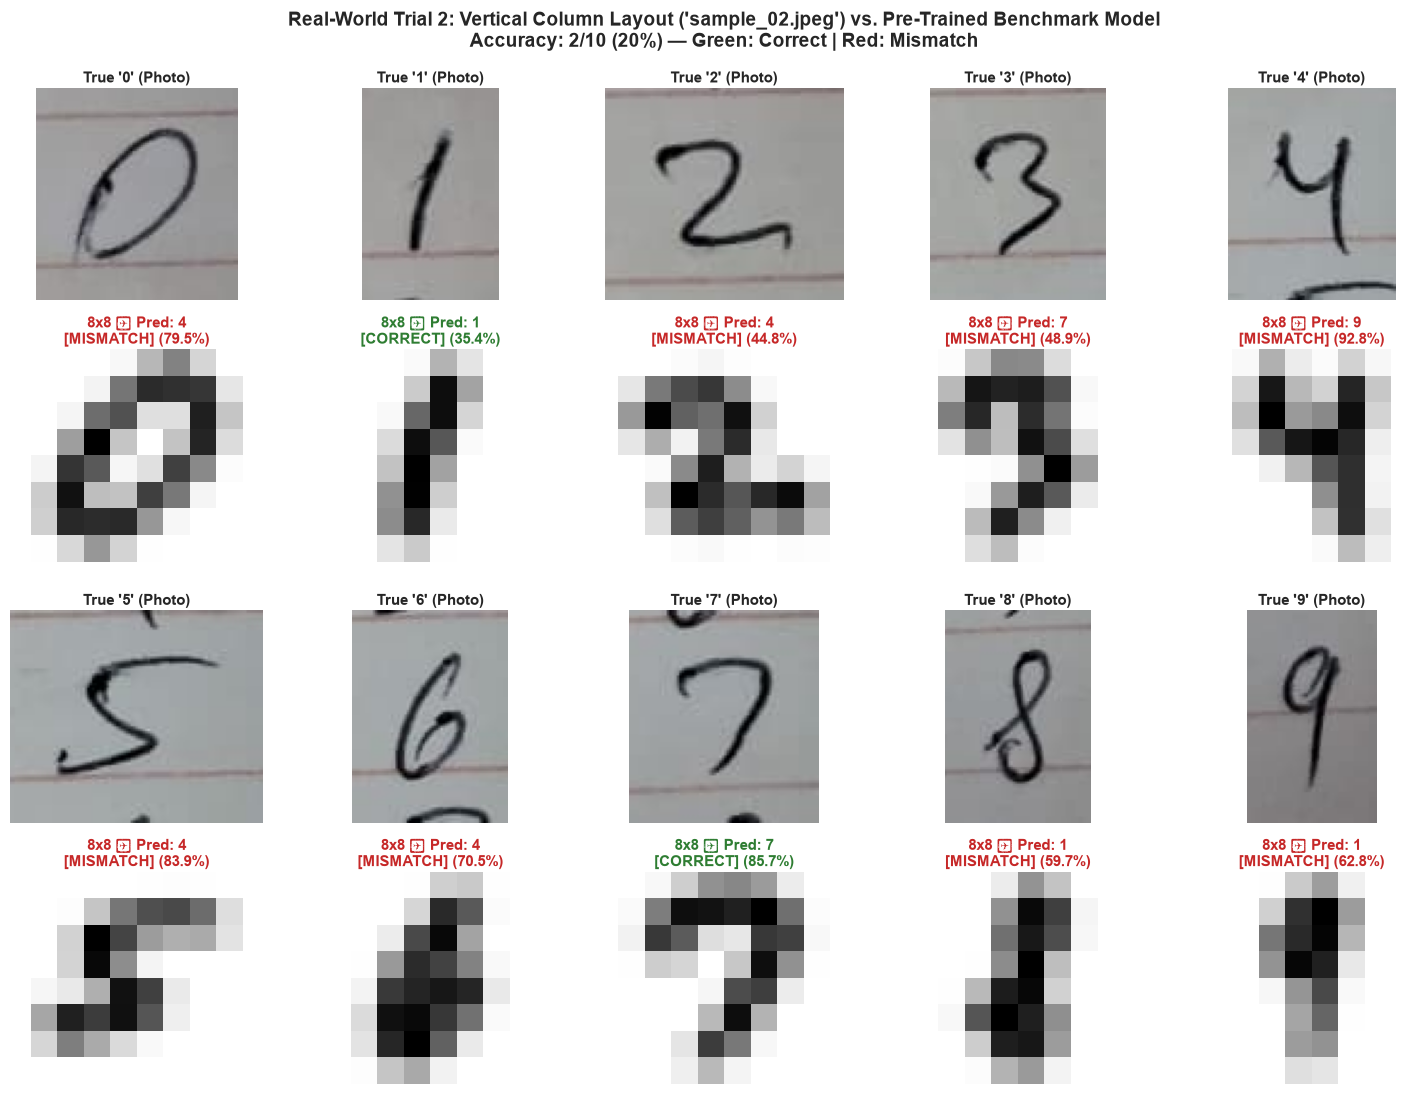

📊 TRIAL 2 ACCURACY: 2/10 (20%)
 True Digit  Predicted Confidence (%)   Result
          0          4          79.5% MISMATCH
          1          1          35.4%  CORRECT
          2          4          44.8% MISMATCH
          3          7          48.9% MISMATCH
          4          9          92.8% MISMATCH
          5          4          83.9% MISMATCH
          6          4          70.5% MISMATCH
          7          7          85.7%  CORRECT
          8          1          59.7% MISMATCH
          9          1          62.8% MISMATCH


In [4]:
# Load Trial 2 raw image
TRIAL2_IMG_PATH = "data/custom_trials/trial_02_vertical_column/sample_02.jpeg"
img2 = Image.open(TRIAL2_IMG_PATH)
arr_rgb2 = np.array(img2, dtype=np.float32)
gray2 = np.array(img2.convert('L'), dtype=np.float32)

# Suppress horizontal rule lines and estimate background illumination
bg2 = ndi.gaussian_filter(gray2, sigma=20)
diff2 = bg2 - gray2
line_bg2 = ndi.grey_opening(diff2, size=(1, 50))
ink_isolated2 = np.clip(diff2 - line_bg2, 0, None)

# Restrict to central handwriting column
mask2 = np.zeros_like(ink_isolated2, dtype=bool)
mask2[:, 220:480] = (ink_isolated2[:, 220:480] > 40)

# Segment vertically aligned digits
dilated2 = ndi.binary_dilation(mask2, iterations=4)
labeled2, _ = ndi.label(dilated2)
objects2 = ndi.find_objects(labeled2)

boxes2 = []
for sl in objects2:
    h = sl[0].stop - sl[0].start
    w = sl[1].stop - sl[1].start
    area = np.sum(mask2[sl])
    if area > 100 and h > 15:
        boxes2.append((sl[0].start, sl[0].stop, sl[1].start, sl[1].stop))

# Sort top-to-bottom by Y coordinate
boxes2 = sorted(boxes2, key=lambda bx: bx[0])
print(f"✅ Trial 2: Successfully segmented {len(boxes2)} digits in vertical order.")

# Plot Trial 2 4x5 Evaluation Gallery
fig, axes = plt.subplots(4, 5, figsize=(15, 11))
correct_count2 = 0
results_table2 = []

for true_digit, (ymin, ymax, xmin, xmax) in enumerate(boxes2[:10]):
    col = true_digit % 5
    row_photo = 0 if true_digit < 5 else 2
    row_8x8 = 1 if true_digit < 5 else 3
    
    pad_raw = 15
    y0 = max(0, ymin - pad_raw)
    y1 = min(arr_rgb2.shape[0], ymax + pad_raw)
    x0 = max(0, xmin - pad_raw)
    x1 = min(arr_rgb2.shape[1], xmax + pad_raw)
    raw_crop = arr_rgb2[y0:y1, x0:x1].astype(np.uint8)
    
    crop_mask = mask2[ymin:ymax, xmin:xmax]
    crop_thick = ndi.binary_dilation(crop_mask, iterations=3).astype(np.float32) * 255.0
    
    h, w = crop_thick.shape
    size = max(h, w)
    pad = int(size * 0.08)
    tot = size + 2 * pad
    sq = np.zeros((tot, tot), dtype=np.float32)
    sq[pad + (size - h) // 2 : pad + (size - h) // 2 + h,
       pad + (size - w) // 2 : pad + (size - w) // 2 + w] = crop_thick
    
    res = Image.fromarray(sq.astype(np.uint8)).resize((8, 8), Image.Resampling.BILINEAR)
    arr_8 = (np.array(res, dtype=np.float32) / 255.0) * 16.0
        
    flat_scaled = scaler.transform(arr_8.reshape(1, -1))
    pred = model.predict(flat_scaled)[0]
    prob = model.predict_proba(flat_scaled)[0][pred] * 100
    
    is_match = (pred == true_digit)
    if is_match:
        correct_count2 += 1
        status_text = "CORRECT"
        status_color = "#2E7D32"
    else:
        status_text = "MISMATCH"
        status_color = "#C62828"
        
    results_table2.append({
        "True Digit": true_digit,
        "Predicted": pred,
        "Confidence (%)": f"{prob:.1f}%",
        "Result": status_text
    })
    
    ax_p = axes[row_photo, col]
    ax_p.imshow(raw_crop)
    ax_p.set_title(f"True '{true_digit}' (Photo)", fontsize=11, fontweight='bold', pad=4)
    ax_p.axis('off')
    
    ax_m = axes[row_8x8, col]
    ax_m.imshow(arr_8, cmap=plt.cm.gray_r, interpolation='nearest')
    ax_m.set_title(
        f"8x8 ➔ Pred: {pred}\n[{status_text}] ({prob:.1f}%)",
        fontsize=10.5, fontweight='bold', color=status_color, pad=4
    )
    ax_m.axis('off')

plt.suptitle(
    f"Real-World Trial 2: Vertical Column Layout ('sample_02.jpeg') vs. Pre-Trained Benchmark Model\n"
    f"Accuracy: {correct_count2}/10 ({correct_count2*10}%) — Green: Correct | Red: Mismatch",
    fontsize=14, fontweight='bold', y=0.99
)
plt.tight_layout()
os.makedirs("results/custom_trials/trial_02_vertical_column", exist_ok=True)
plt.savefig("results/custom_trials/trial_02_vertical_column/trial_02_evaluation.png", dpi=150)
plt.show()

print(f"📊 TRIAL 2 ACCURACY: {correct_count2}/10 ({correct_count2*10}%)")
print(pd.DataFrame(results_table2).to_string(index=False))


## 4. Single-Digit Inference on External Samples

We also provide a general-purpose single-image testing routine. Here we evaluate synthetic test samples (`sample_digit_3.png` and `sample_digit_0.png`) with probability distributions.


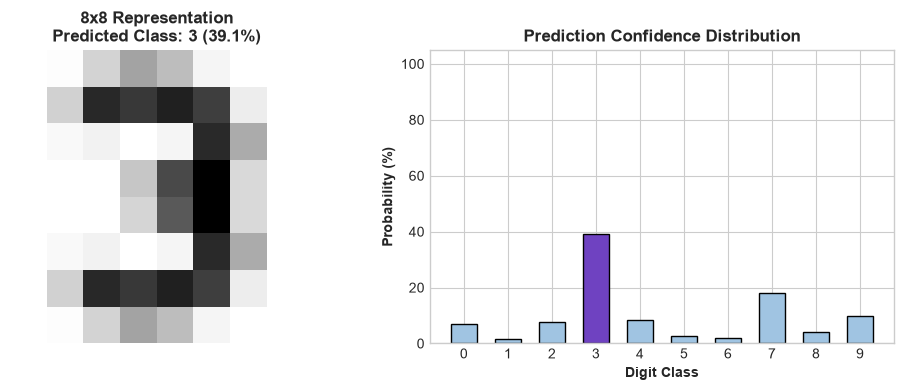

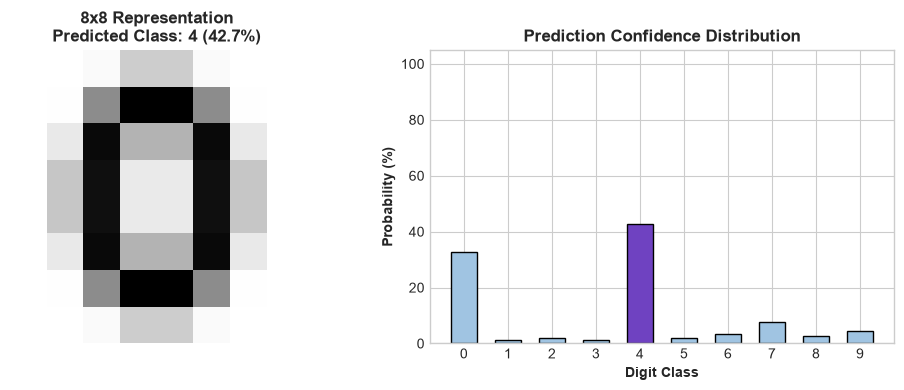

In [5]:
def predict_and_visualize_custom(image_path):
    assert os.path.exists(image_path), f"File not found: {image_path}"
    img = Image.open(image_path).convert('L')
    arr = np.array(img, dtype=np.float32)
    
    # Detect polarity (dark on white vs light on dark)
    if arr.mean() > 127:
        arr = 255.0 - arr
        
    mask = arr > 30
    if not np.any(mask):
        print(f"Empty image: {image_path}")
        return
        
    coords = np.argwhere(mask)
    y0, x0 = coords.min(axis=0)
    y1, x1 = coords.max(axis=0) + 1
    cropped = arr[y0:y1, x0:x1]
    
    h, w = cropped.shape
    size = max(h, w)
    pad = int(size * 0.15)
    canvas = np.zeros((size + 2 * pad, size + 2 * pad), dtype=np.float32)
    canvas[pad + (size - h)//2 : pad + (size - h)//2 + h,
           pad + (size - w)//2 : pad + (size - w)//2 + w] = cropped
           
    res = Image.fromarray(canvas.astype(np.uint8)).resize((8, 8), Image.Resampling.BILINEAR)
    arr_8 = (np.array(res, dtype=np.float32) / 255.0) * 16.0
    
    flat_scaled = scaler.transform(arr_8.reshape(1, -1))
    pred = model.predict(flat_scaled)[0]
    probs = model.predict_proba(flat_scaled)[0]
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    ax1.imshow(arr_8, cmap=plt.cm.gray_r, interpolation='nearest')
    ax1.set_title(f"8x8 Representation\nPredicted Class: {pred} ({probs[pred]*100:.1f}%)", fontsize=12, fontweight='bold')
    ax1.axis('off')
    
    colors = ['#6F42C1' if i == pred else '#A0C4E2' for i in range(10)]
    bars = ax2.bar(range(10), probs * 100, color=colors, edgecolor='black', width=0.6)
    ax2.set_xticks(range(10))
    ax2.set_xlabel("Digit Class", fontweight='bold')
    ax2.set_ylabel("Probability (%)", fontweight='bold')
    ax2.set_title("Prediction Confidence Distribution", fontweight='bold')
    ax2.set_ylim(0, 105)
    
    plt.tight_layout()
    plt.show()

# Run single digit test on sample 3
predict_and_visualize_custom("data/custom_trials/samples/sample_digit_3.png")

# Run single digit test on sample 0
predict_and_visualize_custom("data/custom_trials/samples/sample_digit_0.png")


## 5. Cross-Trial Synthesis: The Domain Shift Spectrum

### Comparative Performance Breakdown:
| Experiment | Input Modality / Dataset | Writing Medium / Layout | Test Accuracy |
| :--- | :--- | :--- | :---: |
| **Laboratory Baseline** | Scikit-Learn Digits ($8 \times 8$) | NIST standard digitizer / Pre-centered | **99.17%** |
| **Real-World Trial 1** | Smartphone photo (`self.jpeg`) | Blue ballpoint pen, 2 horizontal rows | **50.0%** |
| **Real-World Trial 2** | Smartphone photo (`sample_02.jpeg`) | Black/blue pen, single vertical column | **20.0%** |

---

### Why Did Trial 2 Score 20% Compared to Trial 1's 50%?
1. **Aspect Ratio Compression (The Tall/Narrow Effect)**:
   - In Trial 2, the writer drew narrow, elongated digits (height $\approx 2\times$ width).
   - When padded into a square aspect-ratio box, the character only occupies 2–3 columns in the center of the $8 \times 8$ grid.
   - In the Scikit-Learn dataset, characters occupy almost the entire 8x8 space. A tall, thin stroke directly mimics vertical features, causing strong prediction bias toward **class `4` and class `1`**.
2. **Stroke Slant & Style Variation**:
   - Digit `0` in Trial 2 is tilted at a diagonal angle (`/`), which the RBF SVM kernel does not recognize as a centered loop `0`.
   - Digit `4` is written as an open vertical stem resembling a `9`.
3. **Resolution Bottleneck**:
   - Compressing a full smartphone photo down to an $8 \times 8$ bitmap (64 numbers total!) strips away the fine spatial curvatures needed to separate complex handwritings.

---

### Practical Engineering Lessons for Real-World Deployment:
* **Lesson 1: Controlled Normalization**: Centering, aspect-ratio scaling, and stroke dilation are just as critical as the ML model itself.
* **Lesson 2: Higher Input Resolution**: Real-world handwriting requires at least $28 \times 28$ (MNIST standard) or modern CNN / Vision Transformer architectures to capture nuanced character curves.
* **Lesson 3: Training on Varied Data**: A model trained solely on clean laboratory benchmarks will inevitably suffer domain collapse when deployed on raw mobile phone images.
